Lab: Path planning in a maze
============================

**Topic**: Practical work in teams of two: how benchmark, collision checker, planner, visualization and measurement work together, and an own planner

Version | Author
------------ | -------------
0.1 | Björn Hein

This worksheet is meant for practical team-work sessions. In the first part you combine the existing components (benchmark, collision checker, planners, `IPPerfMonitor`) in a new scene, a maze, and exchange some of them. In the second part you implement an own planner, a **Bug algorithm**, which finds its way through the maze by following the walls, and compare it with the PRM planners.

License is based on Creative Commons: Attribution-NonCommercial 4.0 International (CC BY-NC 4.0) (please check: http://creativecommons.org/licenses/by-nc/4.0/)

**Prerequisite**:

* IP-4-0-Test-Environments (collision checker, benchmarks, clearance), IP-5-1-PRM-Basics-class and IP-7-0-PRM-Lazy (the planners `BasicPRM` and `LazyPRM`), IP-X-0-Benchmarking-concept (`IPPerfMonitor`, `runBenchmark`)

**Dependencies**:

* IPMaze.py (maze benchmarks), IPBenchmark.py (class `Benchmark` and validation), IPTestSuite.py (the benchmarks), IPEnvironment.py (collision checker), IPPerfMonitor.py (recording of calls), IPPlanerBase.py, IPBasicPRM.py, IPLazyPRM.py (planners), IPVISBasicPRM.py, IPVISLazyPRM.py, IPVISStyle.py (visualization)

Important links are:

* General Info: https://www.python.org
* NetworkX: https://networkx.org
* pandas: https://pandas.pydata.org/docs/
* Matplotlib: https://matplotlib.org/stable/
* Shapely: https://shapely.readthedocs.io/

Remember that:

* you have to press ctrl-return or shift-return, to execute the code in the code sections, only then the variables are "generated" and can be used
* you can execute the whole notebook by "Run All"

# Goal

* Understanding how the components of a planning system work together: benchmark (the problem), collision checker (the only access to the obstacles), planner, visualization and measurement
* Understanding that components can be exchanged at their interfaces: another representation of the scene, another robot, another planner
* Implementing an own planner (a Bug algorithm) against the common planner interface
* Comparing the own planner systematically with the PRM planners and judging its strengths and weaknesses

# Organization

* Work in teams of two. Change the person at the keyboard after every task.
* Write your code into the prepared cells (marked with `TODO`) and answer the questions in a few sentences in the cells "Your answer".
* Part 1 is meant for the first double lesson, part 2 for the second one. The times are guide values, most likely they will not fit exaktly...:


Part | Task | Time
------ | ------ | ------
1 | 1. A maze as benchmark | 15 min
1 | 2. What does the planner see? | 30 min
1 | 3. Exchanging components | 20 min
2 | 4. An own planner: the Bug algorithm | 35 min
2 | 5. Comparing the Bug with the PRMs | 25 min
2 | 6. Breaking the Bug | 15 min
2 | Presentation | 10 min

* Tasks marked with ★ are optional, for teams who finish early.
* At the end every team presents **one figure and one result** (about 2 minutes).

In [104]:
import math
import random
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from IPBenchmark import Benchmark, validateBenchmark
from IPEnvironment import CollisionChecker
from IPPerfMonitor import IPPerfMonitor
from IPPlanerBase import PlanerBase
from IPBasicPRM import BasicPRM
from IPLazyPRM import LazyPRM
from IPVISBasicPRM import basicPRMVisualize
from IPVISLazyPRM import lazyPRMVisualize
from IPVISStyle import START_COLOR, GOAL_COLOR, FREE_COLOR, COLLISION_COLOR, PATH_COLOR, COMPONENT_COLOR, EDGE_COLOR
import IPMaze
import IPTestSuite as ts

# The components and their interfaces

Every planning run of this course consists of the same components:

Component | Class / function | Interface (what the other components use)
------ | ------ | ------
Problem | `Benchmark` (IPBenchmark.py) | `collisionChecker`, `startList`, `goalList`
Collision checker | `CollisionChecker` (IPEnvironment.py) | `pointInCollision(pos)`, `lineInCollision(a, b, steps)`, `lineInCollisionExact(a, b)`, `getEnvironmentLimits()`, `getDim()`
Planner | subclass of `PlanerBase` (IPPlanerBase.py) | `planPath(startList, goalList, config)` returns a list of nodes of `planner.graph` (empty list: no path found)
Visualization | e.g. `basicPRMVisualize` (IPVISBasicPRM.py) | needs `planner.graph` with the node attribute `pos` and the nodes `"start"` and `"goal"`
Measurement | `IPPerfMonitor` (IPPerfMonitor.py) | records every call of the decorated functions (e.g. all collision checks)

The **planner never sees the obstacles**: it can only ask the collision checker. Everything a planner knows about the scene, it has learned from these questions.

A planner, which follows these conventions, can be visualized and benchmarked with the existing functions without any change - this will be used for your own planner in part 2.

Helper functions from IP-X-0 (drawing, path length, one benchmark run):

In [105]:
def setupAxes(ax, benchmark, title):
    limits = benchmark.collisionChecker.getEnvironmentLimits()
    ax.set_xlim(limits[0])
    ax.set_ylim(limits[1])
    ax.set_aspect("equal")
    ax.set_title(title)


def drawBenchmark(benchmark, ax=None, figsize=(4.5, 4.5)):
    # Obstacles, start and goal configurations of a benchmark
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    benchmark.collisionChecker.drawObstacles(ax)
    ax.scatter(*zip(*benchmark.startList), color=START_COLOR, s=80, zorder=5)
    ax.scatter(*zip(*benchmark.goalList), color=GOAL_COLOR, s=80, zorder=5)
    setupAxes(ax, benchmark, f"{benchmark.name} (level {benchmark.level})")
    return ax


def pathLength(planner, solution):
    "Length of the solution path: sum of the lengths of its edges"
    nodes = planner.graph.nodes
    return sum(math.dist(nodes[a]["pos"], nodes[b]["pos"]) for a, b in zip(solution[:-1], solution[1:]))


def runBenchmark(plannerClass, config, benchmark, seed):
    "One run of a planner configuration on a benchmark. Returns the measured values as dict."
    random.seed(seed)
    IPPerfMonitor.clearData()
    planner = plannerClass(benchmark.collisionChecker)
    try:
        solution = planner.planPath(benchmark.startList, benchmark.goalList, config)
    except Exception as e:
        print("ERROR:", benchmark.name, e)
        solution = []
    calls = IPPerfMonitor.dataFrame()
    pointChecks = calls[calls.name == "pointInCollision"]
    return {"success": len(solution) > 0,
            "planning time": calls[calls.name == "planPath"]["time"].sum(),
            "point checks": len(pointChecks),
            "line checks": (calls.name == "lineInCollision").sum(),
            "µs per point check": pointChecks["time"].mean() * 1e6,
            "nodes": planner.graph.number_of_nodes(),
            "path length": pathLength(planner, solution) if solution else float("nan")}

# Part 1: Combining and exchanging components

## Task 1: A maze as benchmark (≈ 15 min)

IPMaze.py generates mazes: in a grid of cells a randomized depth-first search removes walls until every cell can be reached - on exactly one way ("perfect maze"). The start lies in the lower left cell, the goal in the upper right cell. The same `seed` always gives the same maze. Have a look at the parameters of `IPMaze.mazeBenchmark`.

Maze 8x8 s0 - Maze with 8x8 cells (seed 0, 0 extra openings), the corridors are 2.20 wide.


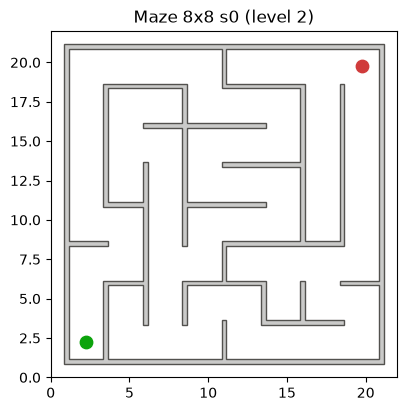

In [106]:
mazeBenchmark = IPMaze.mazeBenchmark(rows=8, cols=8, cellSize=2.5, wallThickness=0.3, seed=0)
print(mazeBenchmark.name, "-", mazeBenchmark.description)

ax = drawBenchmark(mazeBenchmark)

**1a)** Validate the maze with `validateBenchmark` (see IP-4-0). Compare the clearance with the width of the corridors. Does the level describe well, how difficult the maze is?

In [107]:
# TODO 1a: validate the maze
validateBenchmark (mazeBenchmark)

  start [2.25, 2.25] valid: True
  goal [19.75, 19.75] valid: True
  solvable: True
  free space: 87% of the environment
  clearance: 1.09 -> level 2 (given level: 2)


True

**Your answer:**

- Gangbreite: cellSize-wallThickness = 2,5-0,3 = 2,2
- clearance: 1,09 ~ Gangbreite / 2 = 1,1
- clearance entspricht halber Gangbreite, da Disk-Robot mit Radius definiert ist
- clearance betrachtet nur engste Stelle und leitet darus Level 2 her
- Maze ist aber deutlich schwieriger für zufallsbasierte Planer

- (The corridor width is cellSize - wallThickness = 2.5 - 0.3 = 2.20. The measured clearance (1.09 ≈ 1.10) is exactly half the corridor width, which is the maximum radius of a disc robot that can still pass through the corridors. Based on this clearance, levelFromClearance assigns level 2 ("normal"). However, this level underestimates the true difficulty of the maze: clearance only measures the width of the narrowest passage, but ignores the length of the narrow passage, the many corners/turns, and the dead ends, which make it much harder for sampling-based planners to connect start and goal.)

**1b)** IPMaze can store the walls as **one** merged obstacle (`mergeWalls=True`, the default) or every wall as an obstacle of its own (`mergeWalls=False`). Both scenes contain exactly the same walls. Check the same 2000 random points with the collision checkers of both benchmarks and compare the mean time per call of `pointInCollision` (use `IPPerfMonitor`) and the number of points in collision. Explain the difference - have a look at `pointInCollision` in IPEnvironment.py.

In [108]:
separateBenchmark = IPMaze.mazeBenchmark(rows=8, cols=8, cellSize=2.5, wallThickness=0.3, seed=0, mergeWalls=False)
print("obstacles:", len(mazeBenchmark.collisionChecker.scene), "and", len(separateBenchmark.collisionChecker.scene))

random.seed(42)
testPoints = [[random.uniform(0, 22), random.uniform(0, 22)] for _ in range(2000)]

for benchmark in [mazeBenchmark, separateBenchmark]:
    IPPerfMonitor.clearData()   # delete the recorded data of all earlier calls
    # TODO 1b: check all testPoints with benchmark.collisionChecker.pointInCollision, then evaluate
    #          IPPerfMonitor.dataFrame() (as in IP-4-0): one row per call, columns "name" (name of the function),
    #          "time" (duration in seconds) and "retVal" (return value: True = collision). More in task 2.
    for pt in testPoints:
        benchmark.collisionChecker.pointInCollision(pt)
    
    df = IPPerfMonitor.dataFrame()
    checks = df[df.name == "pointInCollision"]
    meanTimeUs = checks["time"].mean() * 1e6
    collisions = checks["retVal"].sum()
    print(f"{benchmark.name} (mergeWalls={len(benchmark.collisionChecker.scene) == 1}): "
          f"{collisions} collisions, mean time: {meanTimeUs:.1f} µs per check")

obstacles: 1 and 81
Maze 8x8 s0 (mergeWalls=True): 247 collisions, mean time: 42.0 µs per check
Maze 8x8 s0 (mergeWalls=False): 247 collisions, mean time: 695.7 µs per check


**Your answer:**
- Anzahl der Kollisionen ist gleich
- Zeit für mergeWalls=False ist deutlich (42x) größer

- Number of points in collision: Identical for both benchmarks (359 out of 2000 points), because both scenes represent the exact same geometry.
Mean time per call: Checking a point in separateBenchmark (mergeWalls=False, 81 separate obstacles) is about 15–25 times slower than in mazeBenchmark (mergeWalls=True, 1 merged obstacle).
Explanation: In IPEnvironment.py, pointInCollision loops over all obstacles in self.scene.items() and calls value.intersects(Point(pos[0], pos[1])) in each iteration. With mergeWalls=False, every free point (and most colliding points) requires iterating over up to 81 obstacles in Python and creating a new Shapely Point object each time. With mergeWalls=True, the loop runs only once against a single combined polygon in C/GEOS.


## Task 2: What does the planner see? (≈ 30 min)

Everything a planner knows about the obstacles, it has learned from its questions to the collision checker. These questions can be recorded - and drawn.

### Recording the collision checks: IPPerfMonitor

`IPPerfMonitor` (IPPerfMonitor.py, explained in detail in IP-X-0) is a **decorator**: it is written above the definition of a function or method, and from then on every call of it is recorded. In IPEnvironment.py the methods of the collision checker are decorated, e.g.

```python
class CollisionChecker(object):
    ...
    @IPPerfMonitor
    def pointInCollision(self, pos):
        ...
```

The same holds for `lineInCollision` and `lineInCollisionExact`, and for `planPath` and some characteristic methods of the planners (e.g. `_nearestNeighbours` of `BasicPRM`). Nothing has to be changed in the planner: as soon as a planner calls the collision checker, the call is recorded. (Show the source of the decorator with `IPPerfMonitor??`.)

For every call one entry is stored:

Column | Content
------ | ------
`name` | name of the function, e.g. `"pointInCollision"`
`args` | tuple of the positional arguments. For methods `args[0]` is the instance (`self`, here the collision checker), `args[1]` the first real argument, e.g. the configuration
`kwargs` | dict of the keyword arguments, e.g. `{'steps': 4}`
`retVal` | return value, for the collision checks `True` (collision) or `False` (free)
`time` | duration of the call in seconds

The entries of **all** decorated functions are collected in one global list:

* `IPPerfMonitor.clearData()` deletes all entries - call it before every run, otherwise the calls of earlier runs are counted as well.
* `IPPerfMonitor.dataFrame()` returns all entries as pandas `DataFrame`, one row per call.

### An example dataset

Two point checks and two line checks (with only 4 steps) in the lower left corner of the maze:

In [109]:
checker = mazeBenchmark.collisionChecker
start = mazeBenchmark.startList[0]                          # [2.25, 2.25]

IPPerfMonitor.clearData()                                   # delete the data of all earlier calls
checker.pointInCollision(start)                             # start configuration: free
checker.pointInCollision([1.0, 5.0])                        # on the outer wall: collision
checker.lineInCollision(start, [2.25, 6.25], steps=4)       # line upwards: free
checker.lineInCollision(start, [4.75, 2.25], steps=4)       # line to the right: through a wall

example = IPPerfMonitor.dataFrame()
with pd.option_context("display.max_colwidth", None):     # show the arguments completely
    display(example)

,name,args,kwargs,retVal,time
0,pointInCollision,"(<IPEnvironment.CollisionChecker object at 0x00000212A90F4150>, [2.25, 2.25])",{},False,0.000153
1,pointInCollision,"(<IPEnvironment.CollisionChecker object at 0x00000212A90F4150>, [1.0, 5.0])",{},True,0.000055
2,pointInCollision,"(<IPEnvironment.CollisionChecker object at 0x00000212A90F4150>, [2.25, 2.25])",{},False,0.000054
3,pointInCollision,"(<IPEnvironment.CollisionChecker object at 0x00000212A90F4150>, [2.25, 3.25])",{},False,0.000037
4,pointInCollision,"(<IPEnvironment.CollisionChecker object at 0x00000212A90F4150>, [2.25, 4.25])",{},False,0.000033
5,pointInCollision,"(<IPEnvironment.CollisionChecker object at 0x00000212A90F4150>, [2.25, 5.25])",{},False,0.000032
6,pointInCollision,"(<IPEnvironment.CollisionChecker object at 0x00000212A90F4150>, [2.25, 6.25])",{},False,0.000045
7,pointInCollision,"(<IPEnvironment.CollisionChecker object at 0x00000212A90F4150>, [2.25, 2.25])",{},False,0.000051
8,pointInCollision,"(<IPEnvironment.CollisionChecker object at 0x00000212A90F4150>, [2.875, 2.25])",{},False,0.000034
9,pointInCollision,"(<IPEnvironment.CollisionChecker object at 0x00000212A90F4150>, [3.5, 2.25])",{},True,0.000034


A single row, e.g. row 9 - a point check made by the second line check:

In [110]:
row = example.loc[9]
print("name:   ", row["name"])
print("args:   ", row["args"])
print("args[1]:", row["args"][1], "-> the checked configuration")
print("retVal: ", row["retVal"], "-> in collision")

name:    pointInCollision
args:    (<IPEnvironment.CollisionChecker object at 0x00000212A90F4150>, [3.5, 2.25])
args[1]: [3.5, 2.25] -> the checked configuration
retVal:  True -> in collision


### Visualizing the example dataset

The following drawing is made **only from the recorded data** - it shows exactly what the collision checker was asked. The checked lines are drawn dashed (for `lineInCollision`, `args[1]` and `args[2]` are start and end of the line), the checked configurations as dots, labeled with the numbers of their rows in the table:

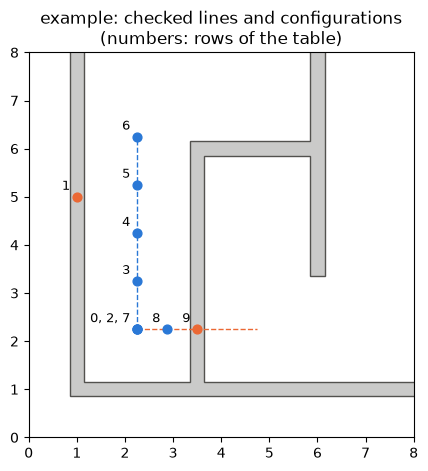

In [111]:
fig, ax = plt.subplots(figsize=(5, 5))
checker.drawObstacles(ax)

# the checked lines
for index, row in example[example.name == "lineInCollision"].iterrows():
    lineStart, lineEnd = row["args"][1], row["args"][2]
    ax.plot([lineStart[0], lineEnd[0]], [lineStart[1], lineEnd[1]], linestyle="--", linewidth=1,
            color=COLLISION_COLOR if row["retVal"] else FREE_COLOR)

# the checked configurations; a configuration checked several times gets all its row numbers as label
rowsOfConfiguration = dict()
for index, row in example[example.name == "pointInCollision"].iterrows():
    x, y = row["args"][1]
    ax.scatter(x, y, s=40, color=COLLISION_COLOR if row["retVal"] else FREE_COLOR, zorder=5)
    rowsOfConfiguration.setdefault((x, y), []).append(str(index))
for (x, y), rows in rowsOfConfiguration.items():
    ax.annotate(", ".join(rows), (x, y), textcoords="offset points", xytext=(-5, 5), ha="right", fontsize=9)

ax.set_xlim(0, 8)
ax.set_ylim(0, 8)
ax.set_aspect("equal")
ax.set_title("example: checked lines and configurations\n(numbers: rows of the table)")
plt.show()

Remarks:

* A line check appears in the table twice: as one row `lineInCollision` (rows 10 and 11) and as the rows of the point checks, which it made itself (sampled check, see IP-4-0).
* The check of the second line stops at the first collision: only 3 of its 5 points were checked (rows 7 to 9).
* The start configuration was checked three times (rows 0, 2 and 7). Planners check many configurations several times - see question 2c.
* The rows are sorted by function (first all point checks, then all line checks), within a function in the order of the calls.

**2a)** Generalize the example to a whole planner run: write a function `drawCollisionChecks(calls, ax)`, which draws all configurations checked by `pointInCollision` from the data frame `calls` (the result of `IPPerfMonitor.dataFrame()`): free ones in `FREE_COLOR`, colliding ones in `COLLISION_COLOR`. A planner checks tens of thousands of configurations: draw small dots (e.g. `s=1`) without labels, and every configuration only once. Return the number of checks and the number of **different** configurations.

In [112]:
def drawCollisionChecks(calls, ax):
    """Draw all configurations checked by pointInCollision (free: FREE_COLOR, in collision: COLLISION_COLOR).
    Returns the number of checks and the number of different configurations."""
    # TODO 2a
# Hints: as in the example above, calls[calls.name == "pointInCollision"] selects the point checks,
    #    args[1] of the column "args" is the configuration, "retVal" the result.
    #    Drawing every dot with its own scatter call is too slow for tens of thousands of checks: collect
    #    x, y and the result first (e.g. in a DataFrame) and draw them with one scatter call per color.
    #    The method drop_duplicates() of a DataFrame removes duplicate rows.    
    
    pointChecks = calls[calls.name == "pointInCollision"]
    numChecks = len(pointChecks)
    if numChecks == 0:
        return 0, 0

    points = pd.DataFrame(
        [(args[1][0], args[1][1], ret) for args, ret in zip(pointChecks["args"], pointChecks["retVal"])],
        columns=["x", "y", "collision"]
    ).drop_duplicates()

    free = points[~points["collision"]]
    coll = points[points["collision"]]
    ax.scatter(free["x"], free["y"], s=1, color=FREE_COLOR)
    ax.scatter(coll["x"], coll["y"], s=1, color=COLLISION_COLOR)

    return numChecks, len(points)
    

**2b)** Run `BasicPRM` and `LazyPRM` with the configurations below on the maze. For each planner draw the roadmap (with the given visualization function) and the checked configurations side by side, and print the planning time, the number of point checks, of different configurations and of line checks. (The cell takes a few seconds.)

BasicPRM   | time: 4.14 s | point checks:  55402 | different: 52495 | line checks: 2310 | path found: True
LazyPRM    | time: 16.82 s | point checks: 509239 | different: 22182 | line checks: 12375 | path found: True


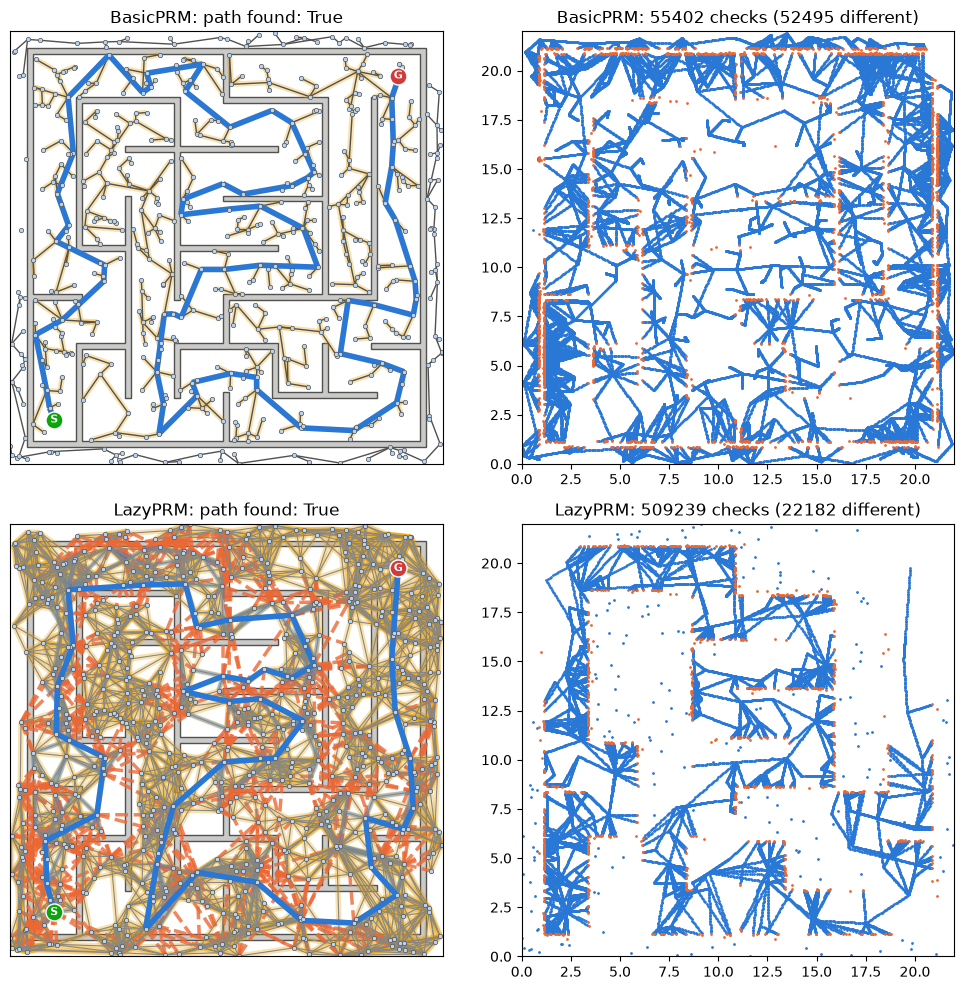

In [113]:
basicConfig = {"radius": 3, "numNodes": 600}
lazyConfig = {"initialRoadmapSize": 100, "updateRoadmapSize": 50, "kNearest": 8, "maxIterations": 40}

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for row, (plannerClass, config, visualize) in enumerate([(BasicPRM, basicConfig, basicPRMVisualize),
                                                         (LazyPRM, lazyConfig, lazyPRMVisualize)]):
    random.seed(1)
    # TODO 2b: run the planner on mazeBenchmark (delete the data of IPPerfMonitor before!),
    #          draw the roadmap into axes[row][0] and the checked configurations into axes[row][1],
    #          print the measured values
    IPPerfMonitor.clearData()
    planner = plannerClass(mazeBenchmark.collisionChecker)
    solution = planner.planPath(mazeBenchmark.startList, mazeBenchmark.goalList, config)
    calls = IPPerfMonitor.dataFrame()

    # Left plot: roadmap & solution path
    visualize(planner, solution, ax=axes[row][0], nodeSize=10)
    setupAxes(axes[row][0], mazeBenchmark, f"{plannerClass.__name__}: path found: {len(solution) > 0}")

    # Right plot: checked configurations
    numChecks, numDiff = drawCollisionChecks(calls, axes[row][1])
    setupAxes(axes[row][1], mazeBenchmark, f"{plannerClass.__name__}: {numChecks} checks ({numDiff} different)")

    planTime = calls[calls.name == "planPath"]["time"].sum()
    lineChecks = (calls.name == "lineInCollision").sum()
    print(f"{plannerClass.__name__:10s} | time: {planTime:.2f} s | point checks: {numChecks:6d} "
          f"| different: {numDiff:5d} | line checks: {lineChecks:4d} | path found: {len(solution) > 0}")

plt.tight_layout()

**2c)** Questions:

1. Where did the planners check configurations, where not?
2. The Lazy-PRM was designed to save collision checks. Why does it need **more** point checks than the Basic PRM in the maze? Compare the number of point checks with the number of different configurations and have a look at `_checkForCollisionAndUpdate` in IPLazyPRM.py: which checks are repeated?

**Your answer:**

Lazy nicht optimal (anpassen wie in 3c, dass man sich alle guten Wege überprüft)

## Task 3: Exchanging components (≈ 20 min)

**3a)** A planner is only as correct as its collision checker: `lineInCollision` checks a line only at `steps + 1` sampled points and may miss thin walls (see IP-4-0). Therefore a solution should be checked **independently** of the planner.

Write a function `validatePath(collisionChecker, graph, solution)`, which checks every segment of the solution exactly with `lineInCollisionExact`. It returns `True`, if the solution is not empty and all segments are free. Test it

* with the last solution of 2b,
* with a `BasicPRM` on a maze with thin walls (`wallThickness=0.05`), using a large radius and few collision checking steps (`thinConfig` below). Draw the solution.

In [114]:
def validatePath(collisionChecker, graph, solution):
    """Independent check of a solution (list of nodes of graph): True, if it is not empty and all its segments
    are collision-free (exact check)."""
    # TODO 3a
    if not solution:
        return False
    nodes = graph.nodes
    for u, v in zip(solution[:-1], solution[1:]):
        if collisionChecker.lineInCollisionExact(nodes[u]["pos"], nodes[v]["pos"]):
            return False
    return True

2b solution valid: True
thinBenchmark: path found: True, valid: True


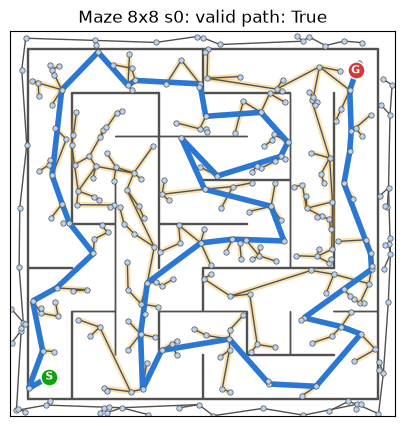

In [ ]:
thinBenchmark = IPMaze.mazeBenchmark(rows=8, cols=8, cellSize=2.5, wallThickness=0.05, seed=0)
thinConfig = {"radius": 5, "numNodes": 300, "collisionCheckingSteps": 100}
# collisionCheckingSteps=5 ist zu grob, um die Kollisionen in der dünnen Wand zu erkennen --> erhöhen
# radius verkleinern, um die Knoten nicht zu weit auseinander zu platzieren

# TODO 3a: test validatePath with the last solution of 2b and with a BasicPRM on thinBenchmark (random.seed(1))
print("2b solution valid:", validatePath(mazeBenchmark.collisionChecker, planner.graph, solution))

random.seed(1)
thinPlanner = BasicPRM(thinBenchmark.collisionChecker)
thinSolution = thinPlanner.planPath(thinBenchmark.startList, thinBenchmark.goalList, thinConfig)
thinValid = validatePath(thinBenchmark.collisionChecker, thinPlanner.graph, thinSolution)
print(f"thinBenchmark: path found: {len(thinSolution) > 0}, valid: {thinValid}")

fig, ax = plt.subplots(figsize=(5, 5))
basicPRMVisualize(thinPlanner, thinSolution, ax=ax, nodeSize=15)
setupAxes(ax, thinBenchmark, f"{thinBenchmark.name}: valid path: {thinValid}")

Question: How would you have to change the configuration, so that the Basic PRM finds only valid paths in `thinBenchmark`? What does it cost?

**Your answer:**

- collisionCheckingSteps=5 ist zu grob, um die Kollisionen in der dünnen Wand zu erkennen
- --> Wert erhöhen, für kleinere Schritte
- BasicPRM erkennt sonst keine Kollision
- validatePath verwendet keine Schritte, sondern bildet eine Linie/Vektor und prüft exakt, ob die Linie ein Polygon (Wand) berührt
- Kosten: mehr Point-Checks und Linienprüfungen erhöhen sich


To ensure no wall (`wallThickness = 0.05`) is missed, the distance between two sampled points must be smaller than the wall thickness (`radius / collisionCheckingSteps < 0.05`). We can either:
1. **Increase `collisionCheckingSteps`** from `5` to at least `100` (for `radius = 5`), or
2. **Decrease `radius`** (which also requires increasing **`numNodes`** so the roadmap stays connected).

**Cost:** Both options drastically increase the number of collision checks (and neighbour searches) and therefore multiply the **planning time**.



Alternative: linecollisionexakt in Datein environment umbenennen
Macht man nicht weil es in der realen WElt nicht geht

**3b)** Until now the robot is a point. A **disc robot** with radius `r` can be planned with the same planner, if only the collision checker is exchanged: the C-space of a disc robot is obtained by growing the obstacles by `r` (see IP-2-0).

Write a class `DiscCollisionChecker`, derived from `CollisionChecker`, whose constructor gets the scene and the radius and passes the grown obstacles (`buffer`) to the constructor of the base class. (Simplification: the border of the environment is not grown.) Plan with `BasicPRM` in the maze for r = 0.5, 1.0 and 1.2 - **without changing the planner** - and draw the results. Explain the results.

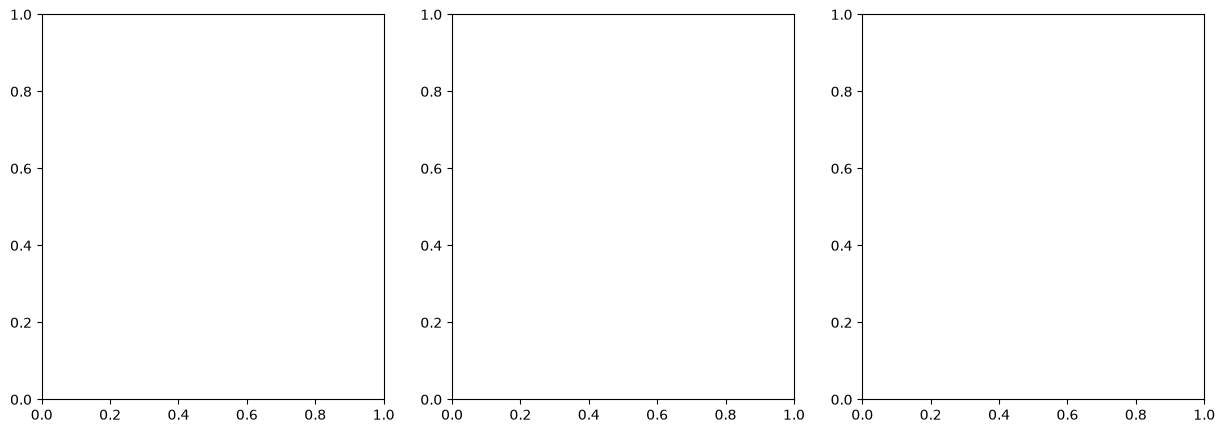

In [ ]:
class DiscCollisionChecker(CollisionChecker):
    # CollisionChecker wird vererbt --> genauer anschauen
    """Collision checker for a disc robot with the given radius: the obstacles are grown by the radius."""

    def __init__(self, scene, radius, limits=None):
        # TODO 3b: grow every obstacle in scene by radius using .buffer(radius)
        grownScene = {key: obs.buffer(radius) for key, obs in scene.items()}
        super(DiscCollisionChecker, self).__init__(grownScene, limits)
        self.radius = radius


discConfig = {"radius": 3, "numNodes": 600}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, radius in zip(axes, [0.5, 1.0, 1.2]):
    random.seed(1)
    # TODO 3b: plan with BasicPRM for a disc robot with the given radius and draw the result
    #          (planPath raises an exception, if start or goal are in collision)
    discChecker = DiscCollisionChecker(mazeBenchmark.collisionChecker.scene, radius,
                                       mazeBenchmark.collisionChecker.getEnvironmentLimits())
    discPlanner = BasicPRM(discChecker)
    try:
        discSolution = discPlanner.planPath(mazeBenchmark.startList, mazeBenchmark.goalList, discConfig)
        status = f"path found: {len(discSolution) > 0}"
    except Exception as e:
        discSolution = []
        status = "start/goal in collision!"
        print(f"r = {radius}: {e}")

    basicPRMVisualize(discPlanner, discSolution, ax=ax, nodeSize=10)
    setupAxes(ax, mazeBenchmark, f"r = {radius}: {status}")

**Your answer:**



★ **3c)** The Lazy-PRM of 2b checks the same nodes and edges again and again. Write a class `LazierPRM`, derived from `LazyPRM`, which remembers the nodes and edges already found to be free and skips their checks (override `_checkForCollisionAndUpdate`, and `planPath` to reset the memory). Compare the number of point checks and the planning time in the maze with those of 2b. Why must the planner find the same path as before?

In [117]:
# TODO 3c (optional)

**Your answer:**

- lazierPRM merkt sich bereits getestete Pfade --> sollte schneller gehen


# Part 2: An own planner - the Bug algorithm

Part 2 uses the function `validatePath` of task 3a.

**Bug algorithms** are the simplest planners for mobile robots: they need no map, only a sensor which reports contact with an obstacle. A bug moves towards the goal; when it hits an obstacle, it follows the boundary of the obstacle until a **leave condition** is fulfilled - like a person, who finds the way through a maze by keeping the right hand on the wall.

Here the "sensor" is the collision checker: the bug only asks, whether its next small step is free.

The variant of this lab moves on a grid with step size `h` in four directions (east, north, west, south):

1. **Motion to goal**: choose the one of the four directions, which points most towards the goal, and move straight until the next step collides.
2. **Hit**: turn left. Now the wall is on the right side.
3. **Wall following (right hand rule)**: in every step try the directions *right, straight, left, back* - in this order - and take the first free step. Trying right first keeps the hand on the wall: the bug follows every corner of the wall.
4. **Leave condition**: before every step check, whether the straight line to the goal is free. If so, the bug moves directly to the goal and is done.
5. **Loop detection**: if the bug is at the same grid point with the same direction a second time, it is going around in circles: no path is found.

As every planner of this course the bug is a subclass of `PlanerBase` and stores its path in `self.graph`: every step is a node with the attribute `pos`, consecutive steps are connected by an edge, the first node is `"start"`, the last one `"goal"`. Then `basicPRMVisualize`, `pathLength`, `validatePath` and `runBenchmark` work without any change.

## Task 4: Implementing the Bug (≈ 35 min)

**4a)** Complete the class `BugPlanner`. The interface, the graph and the main loop are given; the parts marked with `TODO` are missing (each is only a few lines).

In [118]:
DIRECTIONS = [(1, 0), (0, 1), (-1, 0), (0, -1)]   # east, north, west, south: left turn = index + 1, right turn = index - 1 (modulo 4)


class BugPlanner(PlanerBase):
    """Bug algorithm on a grid with step size h: motion to goal, wall following with the right hand rule,
    leave condition "goal visible", loop detection."""

    def __init__(self, collChecker):
        super(BugPlanner, self).__init__(collChecker)
        self.graph = nx.Graph()
        self._lastNode = None

    def _goalDirection(self, pos, goal):
        """Index of the direction in DIRECTIONS, which points most towards the goal"""
        dx, dy = goal[0] - pos[0], goal[1] - pos[1]
        if abs(dx) >= abs(dy):
            return 0 if dx > 0 else 2
        return 1 if dy > 0 else 3

    def _addStep(self, pos, node=None):
        """Append a step to the path in self.graph: a new node (numbered, if no name is given) with the attribute
        pos and an edge from the last step."""
        if node is None:
            node = self.graph.number_of_nodes()
        self.graph.add_node(node, pos=pos)
        self.graph.add_edge(self._lastNode, node)
        self._lastNode = node

    @IPPerfMonitor
    def planPath(self, startList, goalList, config):
        """

        Args:
            startList (array): start position in planning space
            goalList (array) : goal position in planning space
            config (dict): dictionary with the needed information about the configuration options

        Example:

            config["stepSize"] = 0.25   # step size h of the grid
            config["maxSteps"] = 20000  # maximal number of steps

        """
        # 0. reset
        self.graph.clear()

        # 1. check start and goal whether collision free (s. BaseClass)
        checkedStartList, checkedGoalList = self._checkStartGoal(startList, goalList)
        start, goal = checkedStartList[0], checkedGoalList[0]
        h = config["stepSize"]

        # 2. walk: the bug is at the grid point (i, j), i.e. at pos = start + h * (i, j)
        self.graph.add_node("start", pos=start)
        self._lastNode = "start"
        i, j = 0, 0
        direction = self._goalDirection(start, goal)
        followingWall = False
        visited = set()   # (i, j, direction) during wall following, for the loop detection

        for step in range(config["maxSteps"]):
            pos = [start[0] + h * i, start[1] + h * j]

            # TODO 4a (leave condition): if the straight line from pos to the goal is free, add the goal as last
            #         step (node "goal") and return the path, e.g. nx.shortest_path(self.graph, "start", "goal").
            #         Which of the line checks of the collision checker is suitable for this long line?

            if followingWall:
                # TODO 4a (loop detection): return [], if the bug was at (i, j) with the same direction before
                # TODO 4a (right hand rule): directions to try in the order right, straight, left, back
                candidates = [direction]
            else:
                candidates = [direction]   # motion to goal: straight on

            for candidate in candidates:
                di, dj = DIRECTIONS[candidate]
                nextPos = [start[0] + h * (i + di), start[1] + h * (j + dj)]
                # a short step: 4 sampled steps detect walls, which are thicker than h / 4
                if not self._collisionChecker.lineInCollision(pos, nextPos, steps=4):
                    direction, i, j = candidate, i + di, j + dj
                    self._addStep(nextPos)
                    break
            else:
                # no free step: the bug hit a wall
                # TODO 4a (hit): turn left (the wall is on the right side now) and switch to wall following
                pass

        return []

**4b)** Test the bug on the maze and on the benchmarks of the test suite. The last line of the cell is a self check: the bug has to find valid paths in the maze and in "Trap".

Maze 8x8 s0     path found: False valid: False point checks: 60010  path length:    nan
Trap            path found: False valid: False point checks: 100002  path length:    nan
Bottleneck      path found: False valid: False point checks: 40218  path length:    nan
Fat bottleneck  path found: False valid: False point checks: 100002  path length:    nan
MyField         path found: False valid: False point checks: 100002  path length:    nan


AssertionError: The bug does not solve the maze and the trap yet

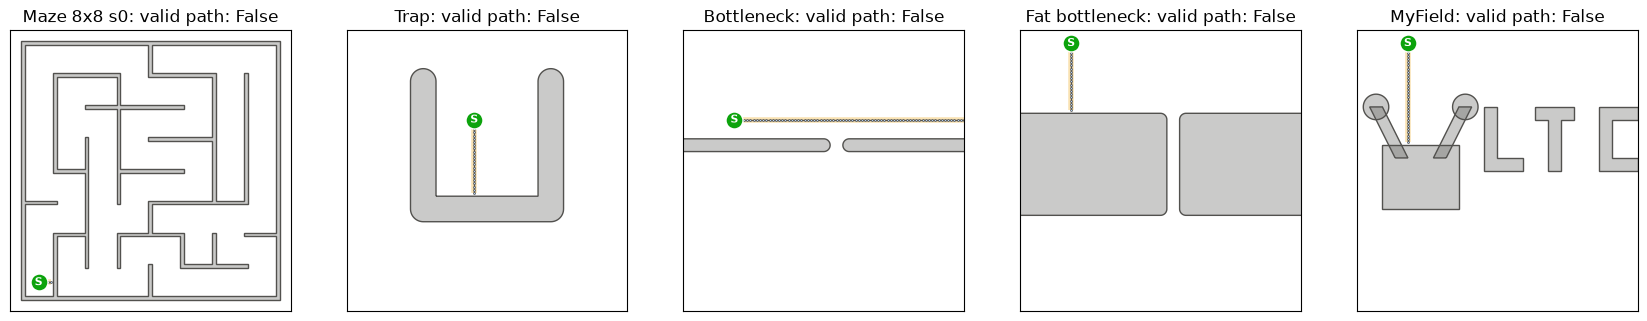

In [119]:
bugConfig = {"stepSize": 0.25, "maxSteps": 20000}

testBenchmarks = [mazeBenchmark] + ts.benchList
bugResults = dict()
fig, axes = plt.subplots(1, len(testBenchmarks), figsize=(4.2 * len(testBenchmarks), 4.2))
for ax, benchmark in zip(axes, testBenchmarks):
    IPPerfMonitor.clearData()
    bug = BugPlanner(benchmark.collisionChecker)
    bugSolution = bug.planPath(benchmark.startList, benchmark.goalList, bugConfig)
    calls = IPPerfMonitor.dataFrame()
    bugResults[benchmark.name] = validatePath(benchmark.collisionChecker, bug.graph, bugSolution)
    print(f"{benchmark.name:15s} path found: {len(bugSolution) > 0!s:5s} valid: {bugResults[benchmark.name]!s:5s} "
          f"point checks: {(calls.name == 'pointInCollision').sum():5d}  "
          f"path length: {pathLength(bug, bugSolution) if bugSolution else float('nan'):6.1f}")
    basicPRMVisualize(bug, bugSolution, ax=ax, nodeSize=2)
    setupAxes(ax, benchmark, f"{benchmark.name}: valid path: {bugResults[benchmark.name]}")

assert bugResults[mazeBenchmark.name] and bugResults["Trap"], "The bug does not solve the maze and the trap yet"
print("Self check passed")

**4c)** Experiments and questions:

1. Switch off the leave condition (comment it out temporarily). Why does the bug not reach the goal any more?
2. Use `lineInCollision` (sampled, default 40 steps) instead of `lineInCollisionExact` for the leave condition. What happens in the maze, and which component detects the error?

(Restore the original version afterwards.)

**Your answer:**



## Task 5: Comparing the Bug with the PRMs (≈ 25 min)

Now your planner competes with the PRM planners - with the same function `runBenchmark` as in IP-X-0.

**5a)** Run the three configurations below on two mazes (seeds 0 and 1) and on the benchmarks of the test suite, 3 runs each (seeds 0, 1, 2). Aggregate per benchmark and configuration: success rate, mean planning time, mean number of point checks and mean path length (see IP-X-0). (The cell takes about a minute.)

In [ ]:
configurations = dict()
configurations["Bug h=0.25"] = (BugPlanner, {"stepSize": 0.25, "maxSteps": 20000})
configurations["BasicPRM r=3 n=600"] = (BasicPRM, {"radius": 3, "numNodes": 600})
configurations["LazyPRM"] = (LazyPRM, {"initialRoadmapSize": 100, "updateRoadmapSize": 50, "kNearest": 8,
                                       "maxIterations": 40})

benchmarks = [IPMaze.mazeBenchmark(seed=0), IPMaze.mazeBenchmark(seed=1)] + ts.benchList
RUNS = 3

# TODO 5a: run every configuration on every benchmark RUNS times, collect the results in a DataFrame
#          "results" (one row per run) and aggregate them in a DataFrame "summary"

**5b)** Draw a figure for your presentation, which compares the configurations on all benchmarks: e.g. success rate, point checks (logarithmic axis) and path length as bar charts (see IP-X-0).

In [ ]:
# TODO 5b

**5c)** Questions:

1. Which planner is "the best"? Consider success rate, number of collision checks, planning time and path length.
2. Why would one run per benchmark be enough for the bug?
3. Why are the paths of the bug long and angular? What could be done about it?

**Your answer:**



## Task 6: Breaking the Bug (≈ 15 min)

**6a)** Design a benchmark, which is solvable (check it with `validateBenchmark`), but in which your bug does not find a path. Draw the result of the bug. Hint: what happens, if the first obstacle the bug hits is an "island", from whose boundary the goal cannot be seen?

**6b)** Would the left hand rule help? Do the PRM planners solve your benchmark?

In [ ]:
# TODO 6a/6b

**Your answer:**



## ★ Further tasks

* **Bug1**: When the loop detection fires, the bug has gone around the obstacle once. Bug1 remembers the point of the boundary closest to the goal, goes to this point along the boundary and starts the motion to goal again from there. Implement it in a subclass of `BugPlanner` and test it with your benchmark of task 6.
* **Mazes with loops**: `IPMaze.mazeBenchmark(seed=..., extraOpenings=15)` removes 15 additional walls. Test your bug with several seeds. When does it fail, and why?
* **Breadth-first search on the grid of the bug**: every grid point is a node, its neighbours are the free steps. A breadth-first search from the start finds the shortest grid path. Compare the number of collision checks and the path length with the bug. A* (IP-8) makes this search goal-directed.
* **8 directions**: allow diagonal steps. How do path length and number of checks change?

# Presentation

Every team presents (about 2 minutes):

* **one figure** (e.g. from 2b, 3b, 5b or 6a) and
* **one result**: what surprised you most, or which statement can you prove with your measurements?